# Download dataset

In [ ]:
!gdown --fuzzy https://drive.google.com/file/d/1vxFk8ypDTqT1J3PteZIaS2d1ApPvFItz/view?usp=sharing
!unzip Merged_Split.zip
!rm -rf Merged_Split.zip

# !gdown --fuzzy https://drive.google.com/file/d/1LndHM7XEIke53m1lIymXbCnuCi9luZWf/view?usp=sharing
# !unzip Trashnet_Split.zip
# !rm -rf Trashnet_Split.zip

Streaming output truncated to the last 5000 lines.
  inflating: Merged_Split/train/cardboard/cardboard_31.jpg  
  inflating: Merged_Split/train/cardboard/cardboard184.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_948.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_1062.jpg  
  inflating: Merged_Split/train/cardboard/CB (208).jpg  
  inflating: Merged_Split/train/cardboard/cardboard38.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_2066.jpg  
  inflating: Merged_Split/train/cardboard/cardboard95.jpg  
  inflating: Merged_Split/train/cardboard/cardboard283.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_1866.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_521.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_60.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_44.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_1210.jpg  
  inflating: Merged_Split/train/cardboard/cardboard_2200.jpg  
  inflating: Merged_Split/tr

In [ ]:
!pip install ai-edge-model-explorer
!pip install -q tensorflow-model-optimization

# Initialize Dataset

Found 14468 images belonging to 6 classes.

Showing augmented images for class: cardboard

cardboard - Color Adjustments Pipeline:


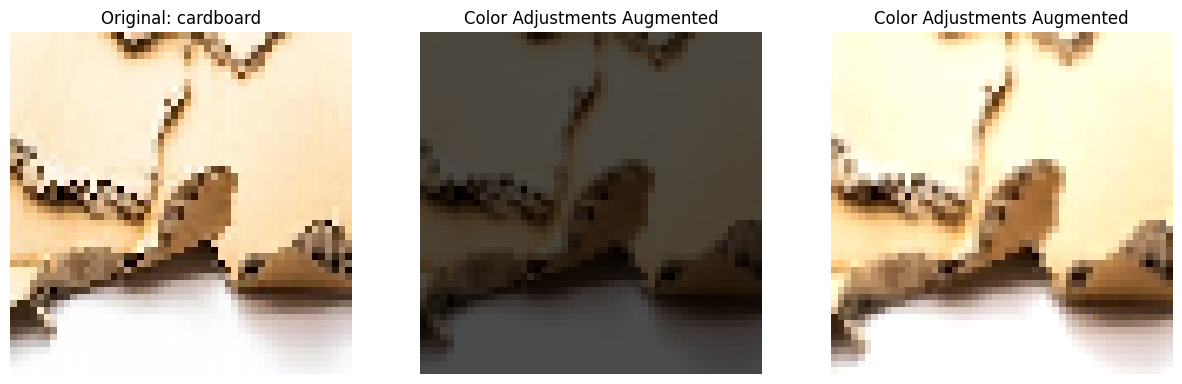


cardboard - Shifting, Rotation, Flips Pipeline:


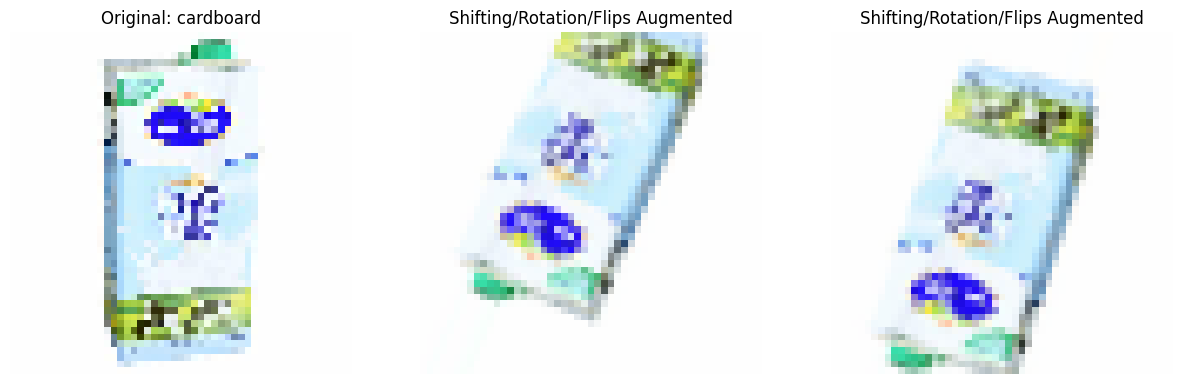


cardboard - Contrast, Zoom, Flip Pipeline:


/usr/local/lib/python3.11/dist-packages/keras/src/legacy/preprocessing/image.py:1263: UserWarning: This ImageDataGenerator specifies `featurewise_center`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/keras/src/legacy/preprocessing/image.py:1273: UserWarning: This ImageDataGenerator specifies `featurewise_std_normalization`, but it hasn't been fit on any training data. Fit it first by calling `.fit(numpy_data)`.
  warnings.warn(


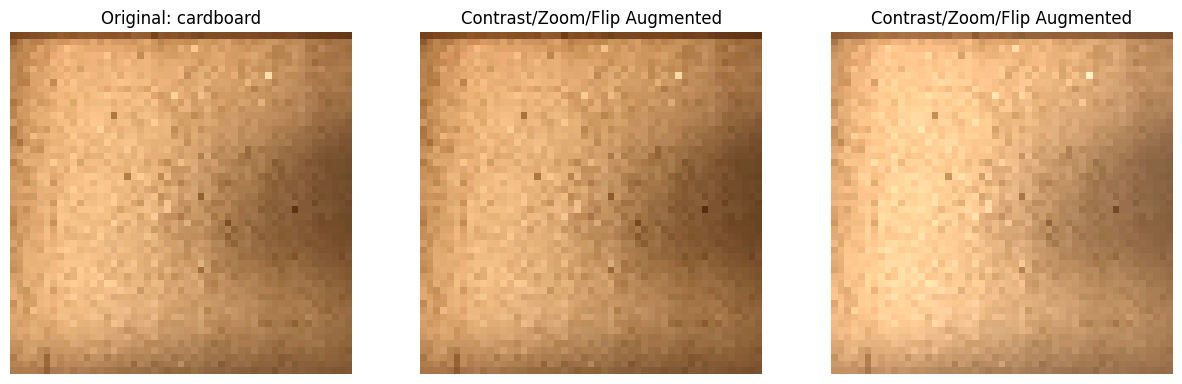


Showing augmented images for class: glass

glass - Color Adjustments Pipeline:


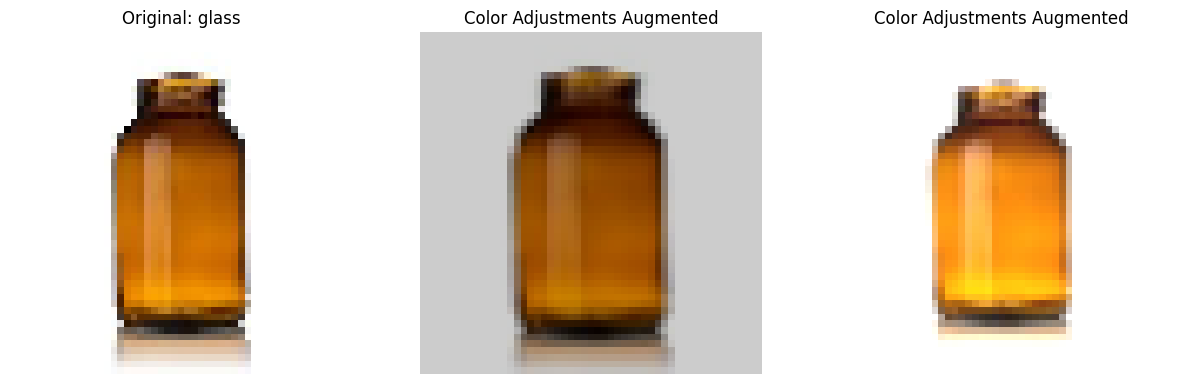


glass - Shifting, Rotation, Flips Pipeline:


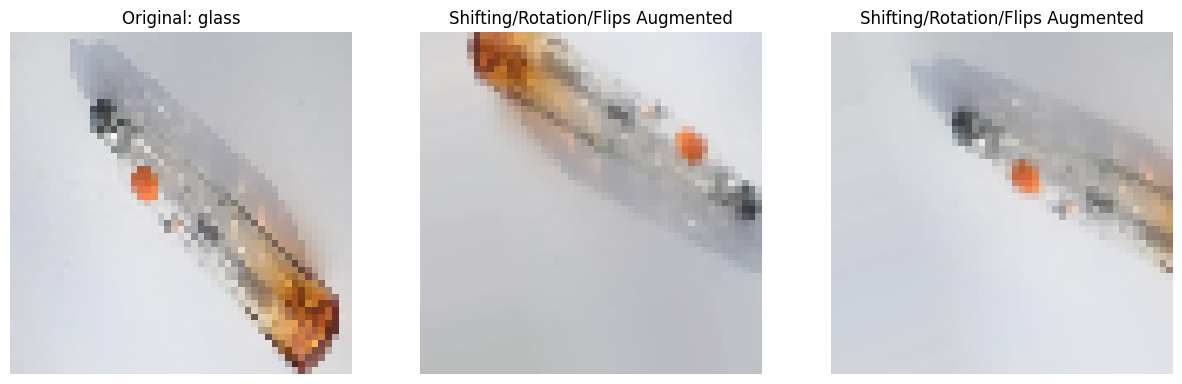


glass - Contrast, Zoom, Flip Pipeline:


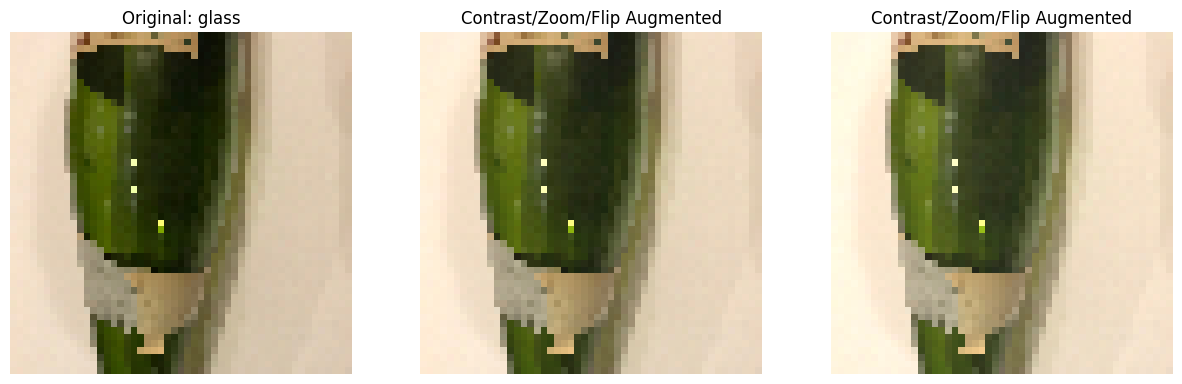


Showing augmented images for class: metal

metal - Color Adjustments Pipeline:


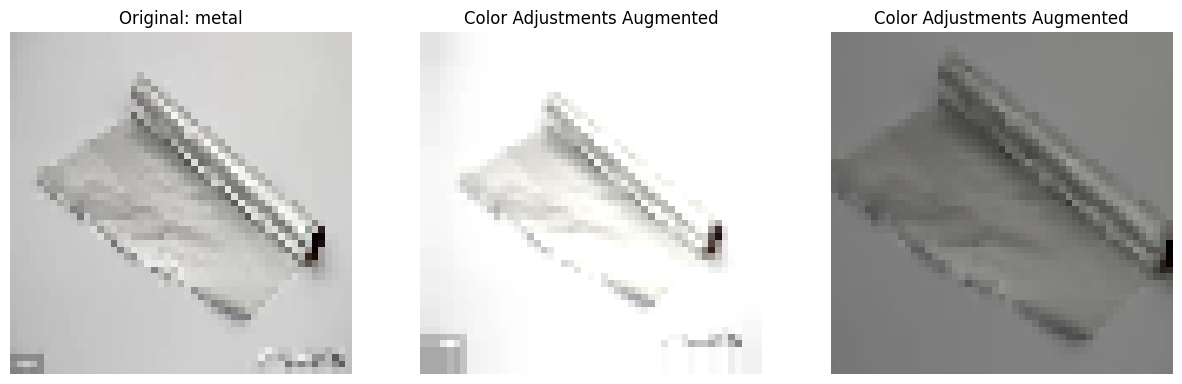


metal - Shifting, Rotation, Flips Pipeline:


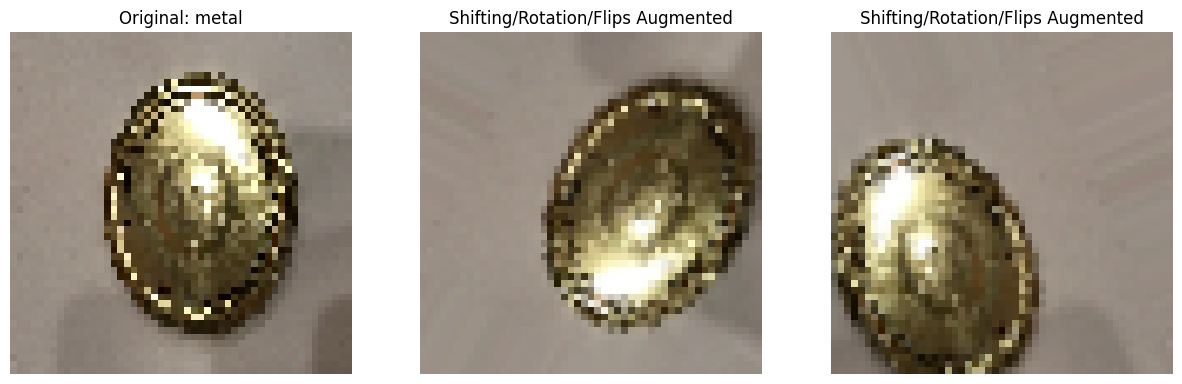


metal - Contrast, Zoom, Flip Pipeline:


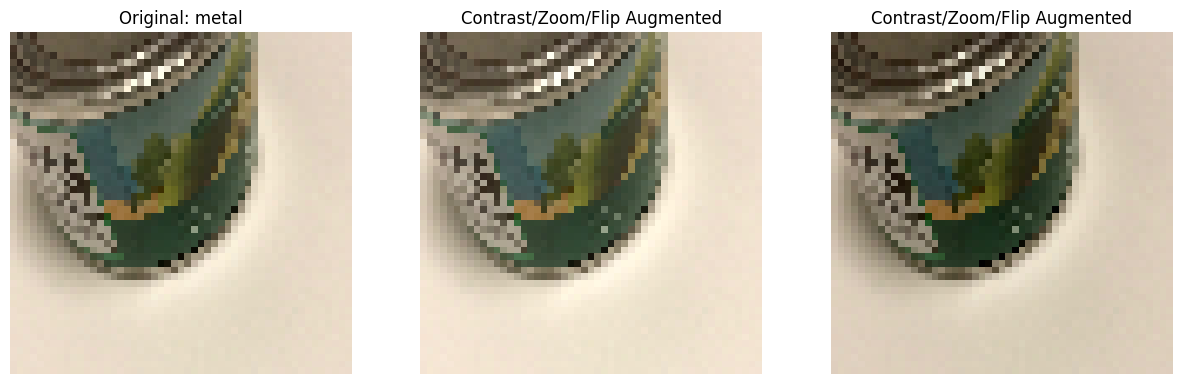


Showing augmented images for class: paper

paper - Color Adjustments Pipeline:


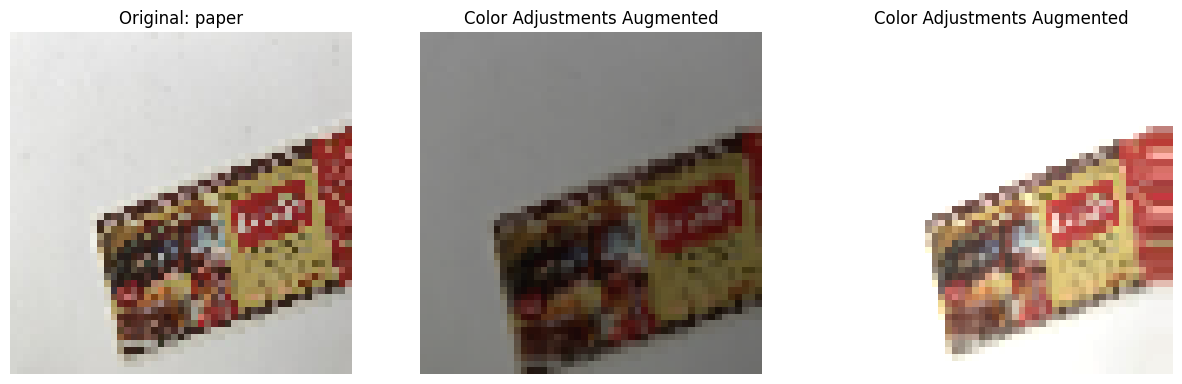


paper - Shifting, Rotation, Flips Pipeline:


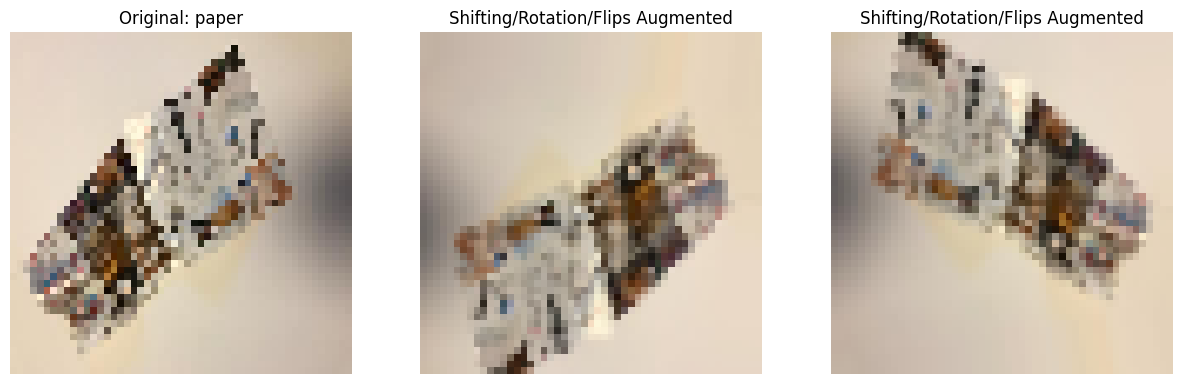


paper - Contrast, Zoom, Flip Pipeline:


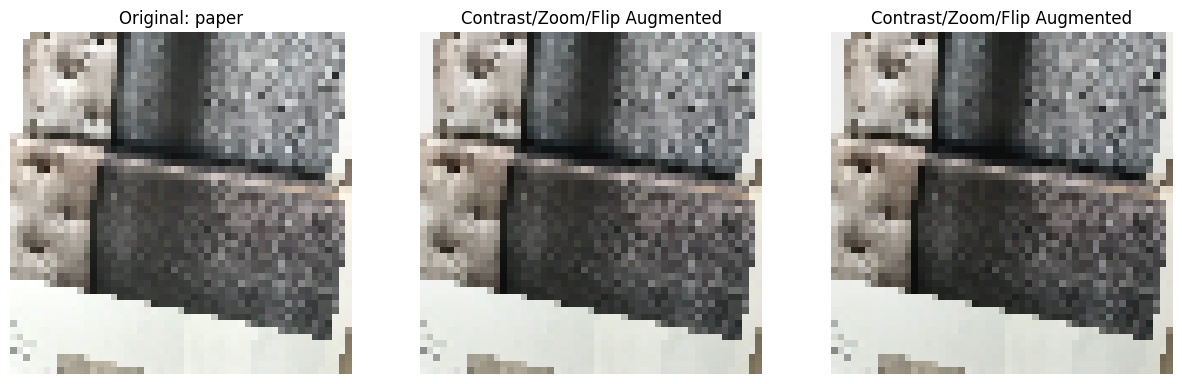


Showing augmented images for class: plastic

plastic - Color Adjustments Pipeline:


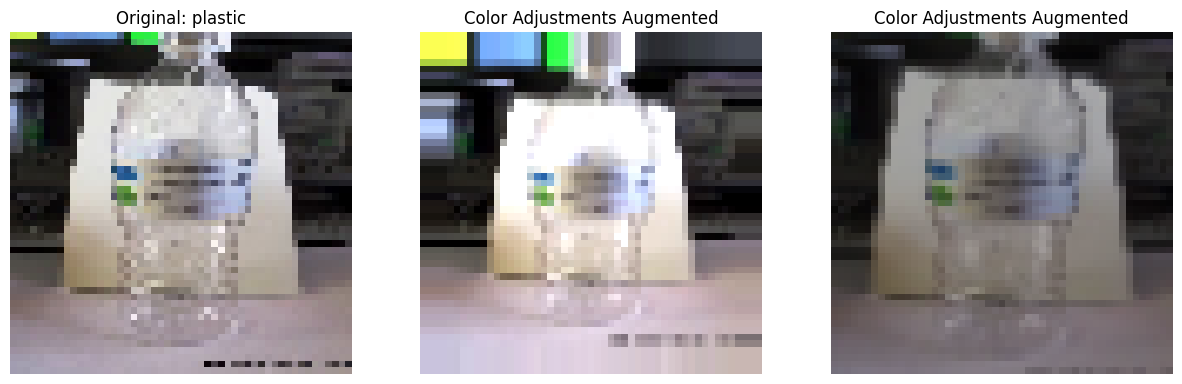


plastic - Shifting, Rotation, Flips Pipeline:


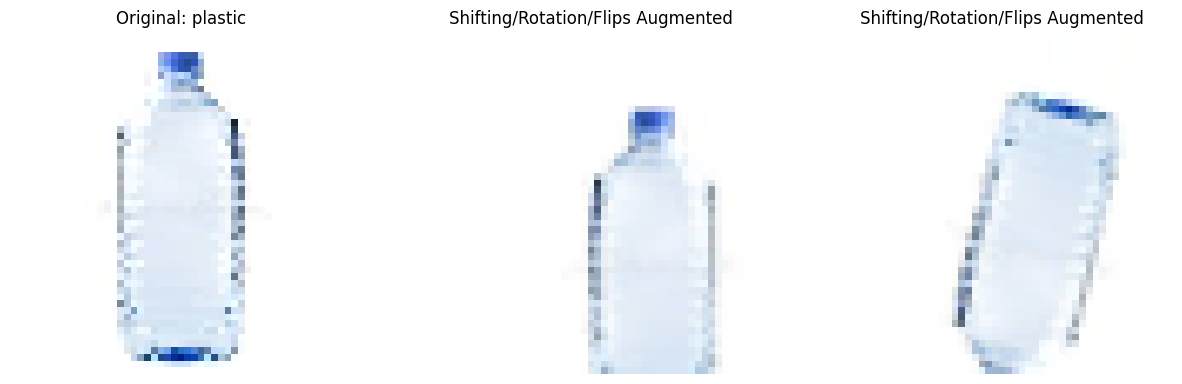


plastic - Contrast, Zoom, Flip Pipeline:


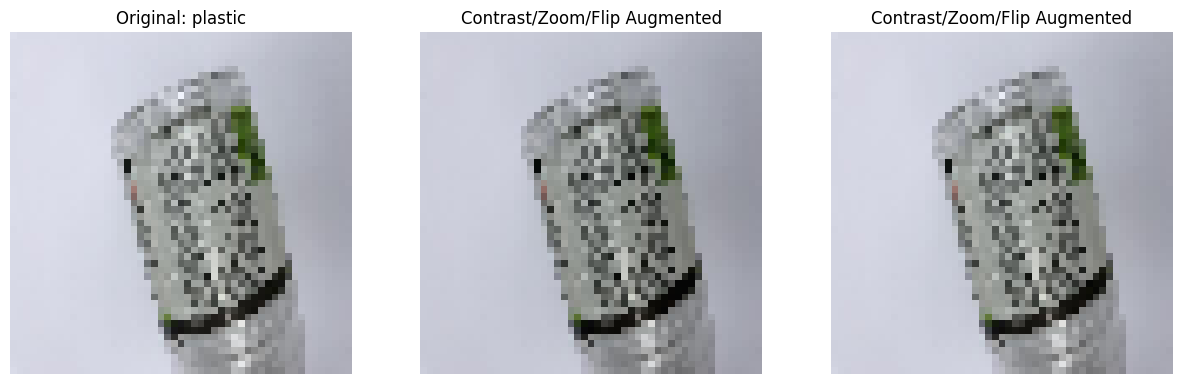


Showing augmented images for class: trash

trash - Color Adjustments Pipeline:


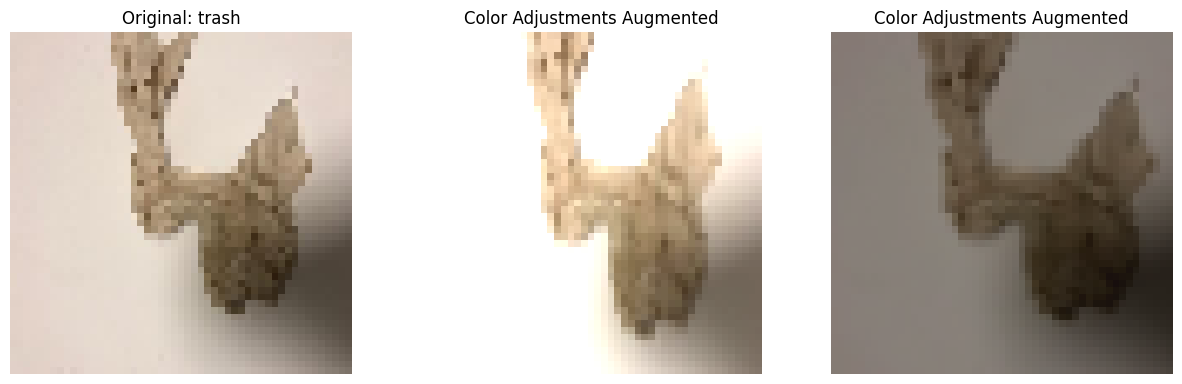


trash - Shifting, Rotation, Flips Pipeline:


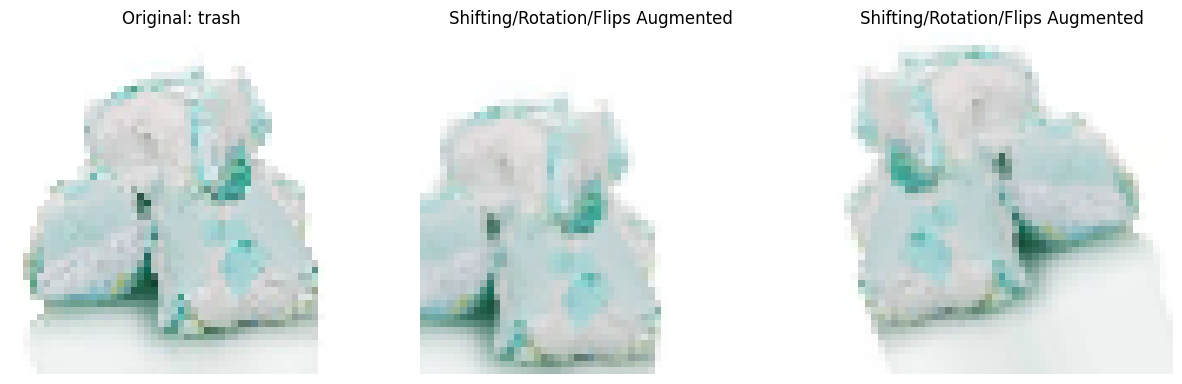


trash - Contrast, Zoom, Flip Pipeline:


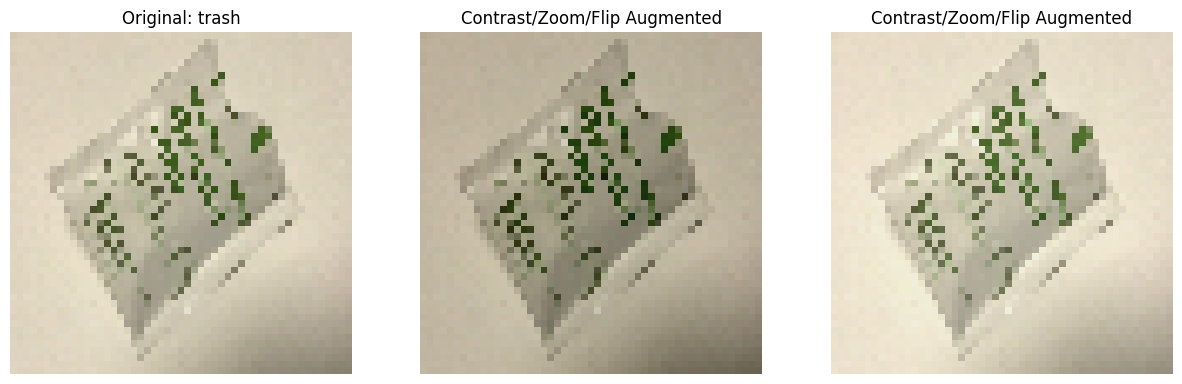

In [ ]:
import tensorflow as tf
import os
import matplotlib.pyplot as plt
import random
import glob
from tensorflow_model_optimization.python.core.keras.compat import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np

# Directory where the dataset is stored
output_dir = '/content/Merged_Split'  # Where to save the split dataset

# Set image dimensions
BATCH_SIZE = 16
IMG_DIM = 51
NUM_CLASSES = 6

# Color adjustment augmentation pipeline
color_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,  # Normalize pixel values to [0, 1]
    brightness_range=[0.3, 1.5],  # Random brightness adjustment
    zoom_range=0.2,               # Random zoom
    channel_shift_range=20.0      # Random channel shift
)

# Shifting, rotation, flips augmentation pipeline
shift_rotate_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,  # Normalize pixel values to [0, 1]
    rotation_range=30,   # Random rotation
    width_shift_range=0.2,  # Random horizontal shift
    height_shift_range=0.2,  # Random vertical shift
    shear_range=0.2,     # Shear transformation
    horizontal_flip=True,  # Random horizontal flip
    vertical_flip=True     # Random vertical flip
)

# Contrast, Zoom, Flip augmentation pipeline (Removed ZCA Whitening)
contrast_zoom_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,  # Normalize pixel values to [0, 1]
    featurewise_center=True,  # Normalize image to have zero mean
    featurewise_std_normalization=True,  # Normalize by the standard deviation
    channel_shift_range=40.0,  # Randomly shift colors of the channels
    cval=0.0  # Value to fill in for pixels outside the boundaries during transformations
)

# Load the dataset and get class indices
train_generator = color_augmentation.flow_from_directory(
    f"{output_dir}/train",
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

class_indices = train_generator.class_indices  # Get class-to-index mapping

# Function to visualize original vs augmented images
def plot_augmented_images(datagen, class_name, class_path, augmentation_type):
    img_paths = glob.glob(f"{class_path}/*.*")  # Match all image types
    if not img_paths:
        print(f"Warning: No images found in {class_path}")
        return

    random_image_path = random.choice(img_paths)
    img = keras.preprocessing.image.load_img(random_image_path, target_size=(IMG_DIM, IMG_DIM))
    img_array = keras.preprocessing.image.img_to_array(img)
    img_array = img_array.reshape((1,) + img_array.shape)  # Reshape for batch processing

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Display the original image
    axes[0].imshow(img)
    axes[0].set_title(f"Original: {class_name}")
    axes[0].axis("off")

    # Generate and display augmented images
    i = 1
    for batch in datagen.flow(img_array, batch_size=1):
        axes[i].imshow(batch[0])
        axes[i].set_title(f"{augmentation_type} Augmented")
        axes[i].axis("off")
        i += 1
        if i == 3:
            break
    plt.show()

# Loop over each class and display original vs augmented images
for class_name in sorted(class_indices.keys()):
    print(f"\nShowing augmented images for class: {class_name}")

    # Display images for color adjustment pipeline
    print(f"\n{class_name} - Color Adjustments Pipeline:")
    plot_augmented_images(color_augmentation, class_name, f"{output_dir}/train/{class_name}", "Color Adjustments")

    # Display images for shifting, rotation, flips pipeline
    print(f"\n{class_name} - Shifting, Rotation, Flips Pipeline:")
    plot_augmented_images(shift_rotate_flip_augmentation, class_name, f"{output_dir}/train/{class_name}", "Shifting/Rotation/Flips")

    # Display images for contrast, zoom, flip pipeline
    print(f"\n{class_name} - Contrast, Zoom, Flip Pipeline:")
    plot_augmented_images(contrast_zoom_flip_augmentation, class_name, f"{output_dir}/train/{class_name}", "Contrast/Zoom/Flip")

In [ ]:
from tqdm import tqdm
import numpy as np

# Function to count images in each class with a progress bar
def count_images_per_class(dataset, dataset_name):
    class_counts = {class_name: 0 for class_name in dataset.class_indices.keys()}
    total_batches = int(np.ceil(dataset.samples / dataset.batch_size))  # Ensure correct number of iterations

    print(f"\nCounting images in {dataset_name} set:")
    for i in tqdm(range(total_batches), desc=f"Processing {dataset_name}"):
        batch_images, batch_labels = next(dataset)  # Get batch from generator
        for label in np.argmax(batch_labels, axis=1):  # Convert one-hot encoding to class index
            class_name = list(dataset.class_indices.keys())[label]
            class_counts[class_name] += 1

    print(f"\n{dataset_name}:")
    for class_name, count in class_counts.items():
        print(f"{class_name} = {count}")

# Count and print the number of images per class with progress bars
count_images_per_class(train_dataset_tf, "Train")
count_images_per_class(val_dataset_tf, "Validation")
count_images_per_class(test_dataset_tf, "Test")


NameError: name 'train_dataset_tf' is not defined

In [ ]:
import os
from tensorflow_model_optimization.python.core.keras.compat import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tqdm.notebook import tqdm  # For progress bar
import glob

# Directory where the augmented images will be saved
augmented_dir = '/content/augmented_train_images'  # Update to your preferred directory
os.makedirs(augmented_dir, exist_ok=True)

# Augmentation pipelines (already defined in previous code)
color_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,
    brightness_range=[0.3, 1.5],
    zoom_range=0.2,
    channel_shift_range=20.0
)

shift_rotate_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    vertical_flip=True
)

contrast_zoom_flip_augmentation = ImageDataGenerator(
    rescale=1.0 / 255,
    featurewise_center=True,
    featurewise_std_normalization=True,
    zca_whitening=True,
    zca_epsilon=1e-06,
    channel_shift_range=40.0,
    cval=0.0,
    interpolation_order=6
)

# Function to save augmented images for a given pipeline
def save_augmented_images(datagen, class_name, class_path):
    # Create a directory to save the augmented images for each class
    class_augmented_dir = os.path.join(augmented_dir, class_name)
    os.makedirs(class_augmented_dir, exist_ok=True)

    # Get all images in the class folder
    img_paths = glob.glob(f"{class_path}/*.jpg")

    # Loop through images and apply augmentation
    for i, img_path in enumerate(tqdm(img_paths, desc=f"Saving augmented images for {class_name}", unit="image")):
        img = keras.preprocessing.image.load_img(img_path, target_size=(IMG_DIM, IMG_DIM))
        img_array = keras.preprocessing.image.img_to_array(img)
        img_array = img_array.reshape((1,) + img_array.shape)  # Reshape for batch processing

        # Apply the augmentation and save images
        for batch in datagen.flow(img_array, batch_size=1, save_to_dir=class_augmented_dir, save_prefix=f"{class_name}_aug", save_format="jpeg"):
            break  # Save one augmented image per original image

# Apply and save augmented images for each class using the three augmentation pipelines
for class_name in sorted(class_indices.keys()):
    print(f"\nProcessing class: {class_name}")

    # Save images for color adjustment pipeline
    save_augmented_images(color_augmentation, class_name, f"{output_dir}/train/{class_name}")

    # Save images for shifting, rotation, flips pipeline
    save_augmented_images(shift_rotate_flip_augmentation, class_name, f"{output_dir}/train/{class_name}")

    # Save images for contrast, zoom, flip pipeline
    save_augmented_images(contrast_zoom_flip_augmentation, class_name, f"{output_dir}/train/{class_name}")

print("\nAugmented images saved successfully!")


Processing class: cardboard


/usr/local/lib/python3.11/dist-packages/keras/src/legacy/preprocessing/image.py:1054: UserWarning: This ImageDataGenerator specifies `zca_whitening` which overrides setting of`featurewise_std_normalization`.
  warnings.warn(


Saving augmented images for cardboard:   0%|          | 0/2312 [00:00<?, ?image/s]

Saving augmented images for cardboard:   0%|          | 0/2312 [00:00<?, ?image/s]

Saving augmented images for cardboard:   0%|          | 0/2312 [00:00<?, ?image/s]

...


Processing class: trash


Saving augmented images for trash:   0%|          | 0/952 [00:00<?, ?image/s]

Saving augmented images for trash:   0%|          | 0/952 [00:00<?, ?image/s]

Saving augmented images for trash:   0%|          | 0/952 [00:00<?, ?image/s]


Augmented images saved successfully!


In [ ]:
for _, labels in train_dataset_tf.take(1):
    print("Labels shape:", labels.shape)
    print("Sample labels:", labels.numpy())


NameError: name 'train_dataset_tf' is not defined

In [ ]:
augmented_train_dir = '/content/augmented_train_images'  # Adjust this path if your augmented train images are stored elsewhere
val_dir = '/content/Merged_Split/val'  # Your validation directory path

# Create the ImageDataGenerator for the augmented images
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255  # You can add other augmentations here if needed
)

val_datagen = ImageDataGenerator(
    rescale=1.0 / 255  # Validation set only has rescaling (no augmentation)
)

# Load the augmented training and validation data
train_dataset_tf = train_datagen.flow_from_directory(
    augmented_train_dir,  # Path to the augmented training images
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical',  # Adjust this to your specific task
    shuffle=True  # Shuffle training data
)

val_dataset_tf = val_datagen.flow_from_directory(
    val_dir,  # Path to the validation images
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical',  # Adjust this to your specific task
    shuffle=False # No shuffle for validation data
)
# Assuming you have a test directory similar to train and val
test_dir = '/content/Merged_Split/test'  # Adjust this path to your test directory

# Create ImageDataGenerator for test data
test_datagen = ImageDataGenerator(
    rescale=1.0 / 255  # Only rescaling for test data
)

# Load the test dataset
test_dataset_tf = test_datagen.flow_from_directory(
    test_dir,  # Path to the test images
    target_size=(IMG_DIM, IMG_DIM),
    batch_size=BATCH_SIZE,
    class_mode='categorical',  # Adjust this to your specific task
    shuffle=False  # No shuffle for test data
)

Found 29418 images belonging to 6 classes.
Found 1810 images belonging to 6 classes.
Found 1812 images belonging to 6 classes.


# Declaring Tensorflow Model

In [ ]:
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import precision_score, recall_score, f1_score as sklearn_f1_score
from tensorflow.keras.callbacks import Callback
from tensorflow_model_optimization.python.core.keras.compat import keras
from tensorflow_model_optimization.python.core.quantization.keras import quantize
from tensorflow.keras import backend as K

# Set the random seeds for reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Image dimensions
IMG_DIM = 51  # Matches your original specification
NUM_CLASSES = 6  # Number of classes in your dataset

# F1 Score Callback for validation
class F1ScoreCallback(Callback):
    def __init__(self, validation_data):
        super().__init__()
        self.validation_data = validation_data

    def on_epoch_end(self, epoch, logs=None):
        # Predict and convert to class indices
        val_pred = np.argmax(self.model.predict(self.validation_data[0]), axis=1)

        # Convert one-hot encoded labels back to class indices
        val_true = np.argmax(self.validation_data[1], axis=1)

        # Calculate F1 score
        f1 = sklearn_f1_score(val_true, val_pred, average='weighted')

        logs['val_f1_score'] = f1
        print(f" - val_f1_score: {f1}")

# Model creation function
def create_model():
    """
    Create a sequential model with depthwise separable convolutions
    and fully connected layers for image classification.

    Returns:
        keras.Sequential: Compiled neural network model
    """
    model = keras.Sequential([
        # Initial Convolution layer with slightly more filters
        keras.layers.Conv2D(32, kernel_size=(3, 3), strides=(2, 2), padding="same", activation='relu', input_shape=(IMG_DIM, IMG_DIM, 3)),
        keras.layers.BatchNormalization(),

        # Depthwise Separable Convolution Block 1 with slightly more filters
        keras.layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        keras.layers.BatchNormalization(),
        keras.layers.Conv2D(48, kernel_size=(1, 1), activation='relu'),  # Slight increase in filters
        keras.layers.BatchNormalization(),
        keras.layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2)),

        # Depthwise Separable Convolution Block 2 with slightly more filters
        keras.layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        keras.layers.BatchNormalization(),
        keras.layers.Conv2D(96, kernel_size=(1, 1), activation='relu'),  # Slight increase in filters
        keras.layers.BatchNormalization(),
        keras.layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2)),
        keras.layers.Dropout(0.2),  # Dropout after pooling

        # Depthwise Separable Convolution Block 3 with slightly more filters
        keras.layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        keras.layers.BatchNormalization(),
        keras.layers.Conv2D(128, kernel_size=(1, 1), activation='relu'),  # Same filter size as original
        keras.layers.BatchNormalization(),
        keras.layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2)),
        keras.layers.Dropout(0.2),  # Dropout after this block

        # Final Depthwise Separable Convolution Block with reduced filters
        keras.layers.DepthwiseConv2D(kernel_size=(3, 3), padding="same", activation='relu'),
        keras.layers.BatchNormalization(),
        keras.layers.Conv2D(128, kernel_size=(1, 1), activation='relu'),  # Same filter size as original
        keras.layers.BatchNormalization(),
        keras.layers.GlobalAveragePooling2D(),  # GlobalAveragePooling reduces parameters

        # Fully connected layers with slightly more units
        keras.layers.Dense(64, activation='relu'),  # Same dense layer size as original
        keras.layers.Dropout(0.2),  # Dropout layer after first dense layer
        keras.layers.Dense(32, activation='relu'),  # Same dense layer size as original
        keras.layers.Dropout(0.2),  # Dropout layer after second dense layer

        # Output layer with softmax activation for multi-class classification
        keras.layers.Dense(6, activation='softmax')  # 6 classes with softmax activation
    ])

    # Compile the model
    model.compile(
        loss=keras.losses.categorical_crossentropy,
        optimizer=keras.optimizers.Adam(learning_rate=0.0001),
        metrics=['accuracy']
    )

    return model

# Create the model
tf_model = create_model()

# Save the model
keras_file = "model.h5"
keras.models.save_model(tf_model, keras_file)

# Print model summary
tf_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 26, 26, 32)        896       
                                                                 
 batch_normalization (Batch  (None, 26, 26, 32)        128       
 Normalization)                                                  
                                                                 
 depthwise_conv2d (Depthwis  (None, 26, 26, 32)        320       
 eConv2D)                                                        
                                                                 
 batch_normalization_1 (Bat  (None, 26, 26, 32)        128       
 chNormalization)                                                
                                                                 
 conv2d_1 (Conv2D)           (None, 26, 26, 48)        1584      
                                                        

<ipython-input-7-aab656867e86>:108: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  keras.models.save_model(tf_model, keras_file)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Train Model

0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

Epoch 1/220
1839/1839 [==============================] - ETA: 0s - loss: 1.4745 - accuracy: 0.4238
Epoch 1: val_accuracy improved from -inf to 0.54696, saving model to /content/best_model.h5


/usr/local/lib/python3.11/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


57/57 [==============================] - 2s 22ms/step
 - val_f1_score: 0.5471862017091325
1839/1839 [==============================] - 143s 75ms/step - loss: 1.4745 - accuracy: 0.4238 - val_loss: 1.1878 - val_accuracy: 0.5470 - val_f1_score: 0.5472
Epoch 2/220
1838/1839 [============================>.] - ETA: 0s - loss: 1.2623 - accuracy: 0.5297
Epoch 2: val_accuracy did not improve from 0.54696
57/57 [==============================] - 1s 22ms/step
 - val_f1_score: 0.5224806058560961
1839/1839 [==============================] - 136s 74ms/step - loss: 1.2624 - accuracy: 0.5296 - val_loss: 1.3179 - val_accuracy: 0.5227 - val_f1_score: 0.5225
Epoch 3/220
1838/1839 [============================>.] - ETA: 0s - loss: 1.1612 - accuracy: 0.5751
Epoch 3: val_accuracy did not improve from 0.54696
57/57 [==============================] - 1s 25ms/step
 - val_f1_score: 0.46067831639402945
1839/1839 [==============================] - 153s 83ms/step - loss: 1.1613 - accuracy: 0.5751 - val_loss: 1.414

...

57/57 [==============================] - 1s 23ms/step
 - val_f1_score: 0.8737897845819808
1839/1839 [==============================] - 157s 85ms/step - loss: 0.4021 - accuracy: 0.8639 - val_loss: 0.4580 - val_accuracy: 0.8729 - val_f1_score: 0.8738
Epoch 157/220
1838/1839 [============================>.] - ETA: 0s - loss: 0.3976 - accuracy: 0.8635
Epoch 157: val_accuracy did not improve from 0.87293
57/57 [==============================] - 1s 23ms/step
 - val_f1_score: 0.862679674275502
1839/1839 [==============================] - 155s 85ms/step - loss: 0.3977 - accuracy: 0.8634 - val_loss: 0.4702 - val_accuracy: 0.8608 - val_f1_score: 0.8627
Epoch 158/220
1838/1839 [============================>.] - ETA: 0s - loss: 0.3989 - accuracy: 0.8634
Epoch 158: val_accuracy did not improve from 0.87293
57/57 [==============================] - 1s 23ms/step
 - val_f1_score: 0.8666858528308543
1839/1839 [==============================] - 145s 79ms/step - loss: 0.3989 - accuracy: 0.8634 - val_loss:

/usr/local/lib/python3.11/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


57/57 [==============================] - 1s 23ms/step
 - val_f1_score: 0.8752620801500087
1839/1839 [==============================] - 156s 85ms/step - loss: 0.4035 - accuracy: 0.8638 - val_loss: 0.4299 - val_accuracy: 0.8746 - val_f1_score: 0.8753
Epoch 174/220
1839/1839 [==============================] - ETA: 0s - loss: 0.3910 - accuracy: 0.8671
Epoch 174: val_accuracy did not improve from 0.87459
57/57 [==============================] - 1s 24ms/step
 - val_f1_score: 0.8549078956604685
1839/1839 [==============================] - 154s 84ms/step - loss: 0.3910 - accuracy: 0.8671 - val_loss: 0.4718 - val_accuracy: 0.8541 - val_f1_score: 0.8549
Epoch 175/220
1838/1839 [============================>.] - ETA: 0s - loss: 0.3925 - accuracy: 0.8660
Epoch 175: val_accuracy did not improve from 0.87459
57/57 [==============================] - 1s 23ms/step
 - val_f1_score: 0.8590597720840404
1839/1839 [==============================] - 156s 85ms/step - loss: 0.3924 - accuracy: 0.8660 - val_loss

/usr/local/lib/python3.11/dist-packages/tf_keras/src/engine/training.py:3098: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(



Model training complete and saved to /content/saved_model.h5

Training metrics saved to /content/drive/MyDrive/main model/training_metrics.csv
114/114 [==============================] - 30s 258ms/step
Validation F1 Score: 0.8714


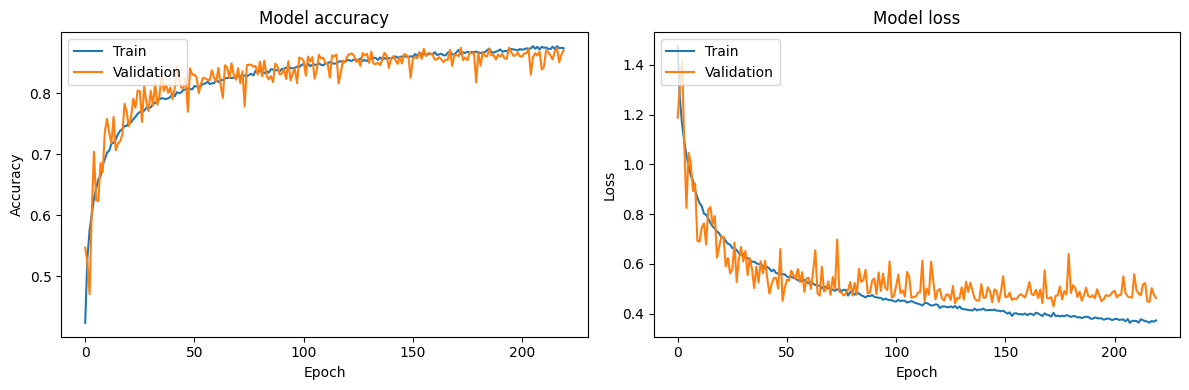

In [ ]:
from tqdm.keras import TqdmCallback
import numpy as np
import tensorflow as tf
from sklearn.metrics import f1_score as sklearn_f1_score
import pandas as pd
# Recompile the model without custom F1 score metric
tf_model.compile(
    loss=keras.losses.categorical_crossentropy,
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    metrics=['accuracy'],
    run_eagerly=False  # Set to True only for debugging
)

# F1 Score Callback
class F1ScoreCallback(tf.keras.callbacks.Callback):
    def __init__(self, validation_data):
        super().__init__()
        self.validation_data = validation_data

    def on_epoch_end(self, epoch, logs=None):
        # Predict and convert to class indices
        val_pred = np.argmax(self.model.predict(self.validation_data[0]), axis=1)

        # Convert one-hot encoded labels back to class indices
        val_true = np.argmax(self.validation_data[1], axis=1)

        # Calculate F1 score
        f1 = sklearn_f1_score(val_true, val_pred, average='weighted')

        logs['val_f1_score'] = f1
        print(f" - val_f1_score: {f1}")

# Calculate steps per epoch for training and validation
steps_per_epoch_train = np.ceil(train_dataset_tf.samples / BATCH_SIZE).astype(int)
steps_per_epoch_val = np.ceil(val_dataset_tf.samples / BATCH_SIZE).astype(int)

# Number of epochs for training
epochs = 220
# Learning rate scheduler
# scheduler = tf.keras.callbacks.ReduceLROnPlateau(
#     monitor='val_loss',
#     factor=0.5,
#     patience=3,
#     min_lr=1e-6,
#     verbose=1
# )

# Model checkpoint to save the best model
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath='/content/best_model.h5',
    monitor='val_accuracy',
    mode='max',
    save_best_only=True,
    verbose=1
)

# F1 Score Callback (requires converting generator to numpy arrays)
val_X, val_y = [], []
for _ in range(steps_per_epoch_val):
    batch_X, batch_y = next(val_dataset_tf)
    val_X.append(batch_X)
    val_y.append(batch_y)
val_X = np.vstack(val_X)
val_y = np.vstack(val_y)

f1_callback = F1ScoreCallback(validation_data=(val_X, val_y))

# Train the model with progress bar
history = tf_model.fit(
    train_dataset_tf,
    steps_per_epoch=steps_per_epoch_train,
    epochs=epochs,
    validation_data=val_dataset_tf,
    validation_steps=steps_per_epoch_val,
    callbacks=[
        TqdmCallback(),  # Progress bar
        #scheduler,       # Learning rate scheduler
        checkpoint,      # Model checkpoint
        f1_callback      # F1 Score Callback
    ]
)

# Save the trained model to /content directory
tf_model.save('/content/saved_model.h5')

print("\nModel training complete and saved to /content/saved_model.h5")
# Save training metrics to CSV
history_dict = history.history
num_epochs = len(history_dict['loss'])

# Add val_f1_score from callback if not present
if 'val_f1_score' not in history_dict:
    history_dict['val_f1_score'] = f1_callback.f1_scores

history_df = pd.DataFrame({
    'epoch': range(1, num_epochs + 1),
    'accuracy': history_dict['accuracy'],
    'loss': history_dict['loss'],
    'val_accuracy': history_dict['val_accuracy'],
    'val_loss': history_dict['val_loss'],
    'val_f1_score': history_dict['val_f1_score'],
})

csv_path = '/content/drive/MyDrive/main model/training_metrics.csv'
history_df.to_csv(csv_path, index=False)
print(f"\nTraining metrics saved to {csv_path}")
# For evaluation after training, use sklearn's f1_score with generator
# Get predictions
val_dataset_tf.reset()
val_preds = tf_model.predict(val_dataset_tf, steps=steps_per_epoch_val)
val_pred_classes = np.argmax(val_preds, axis=-1)

# Get true labels
val_dataset_tf.reset()
true_labels = []
for i in range(steps_per_epoch_val):
    _, batch_y = next(val_dataset_tf)
    true_labels.append(batch_y)
true_labels = np.vstack(true_labels)
true_classes = np.argmax(true_labels[:len(val_pred_classes)], axis=-1)

# Calculate F1 score
val_f1 = sklearn_f1_score(true_classes, val_pred_classes, average='weighted')
print(f"Validation F1 Score: {val_f1:.4f}")

# Optional: Visualize training history
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1,2,2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.tight_layout()
plt.show()

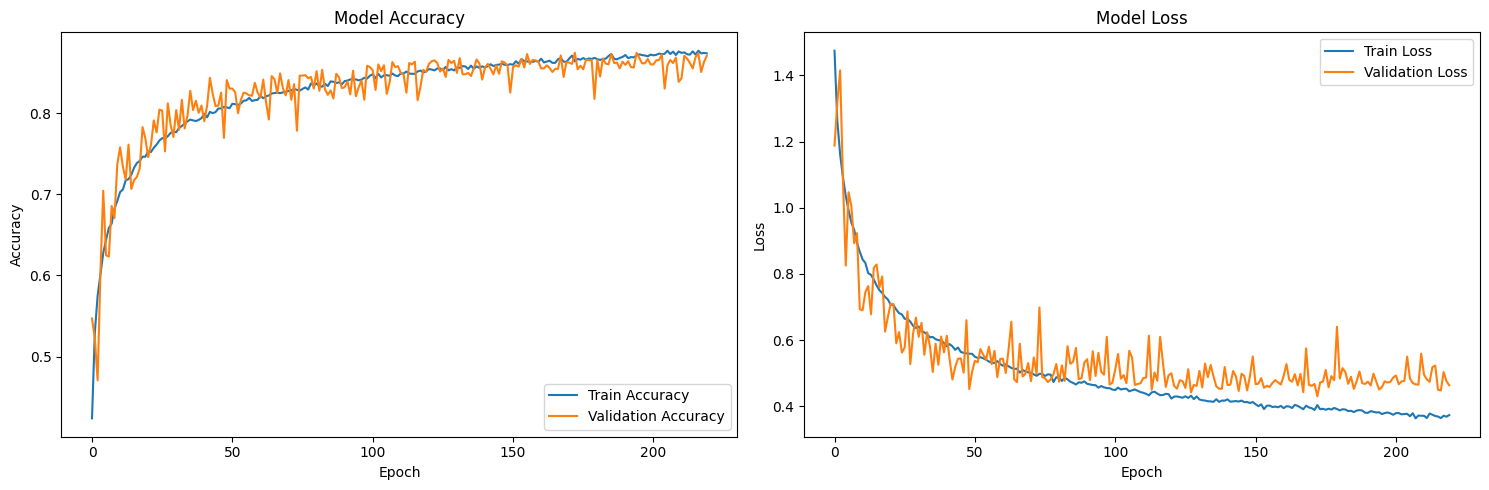

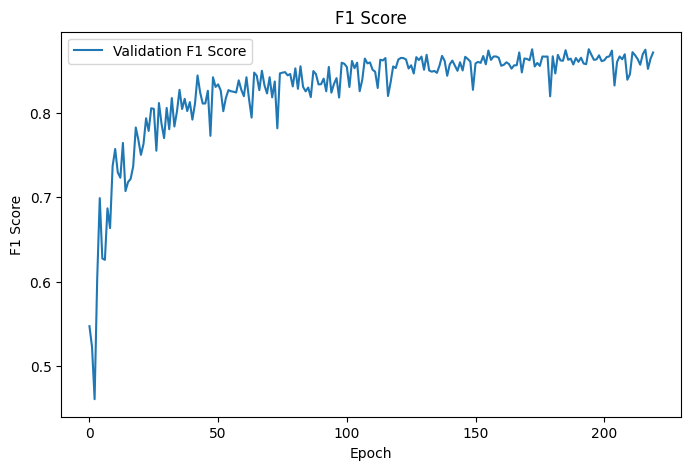

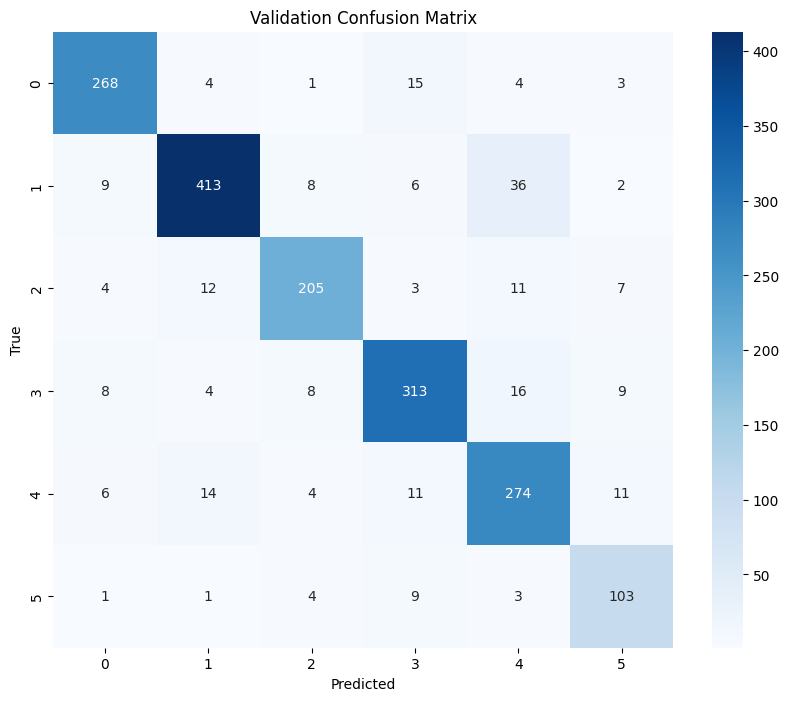

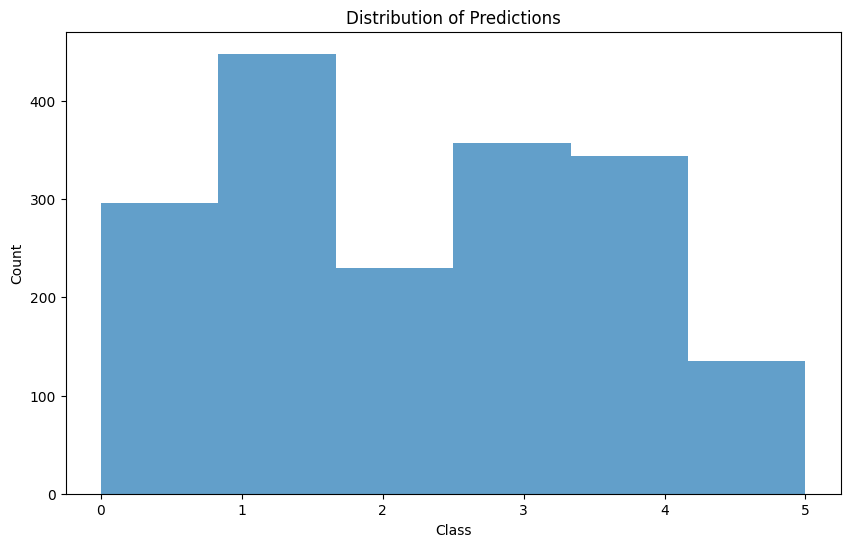

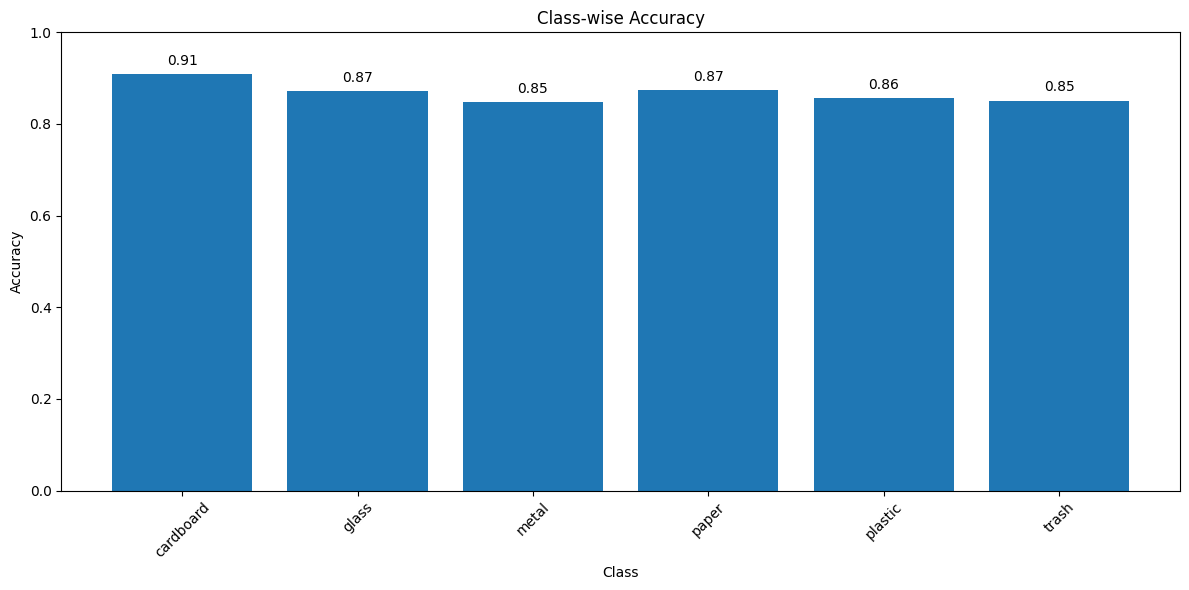

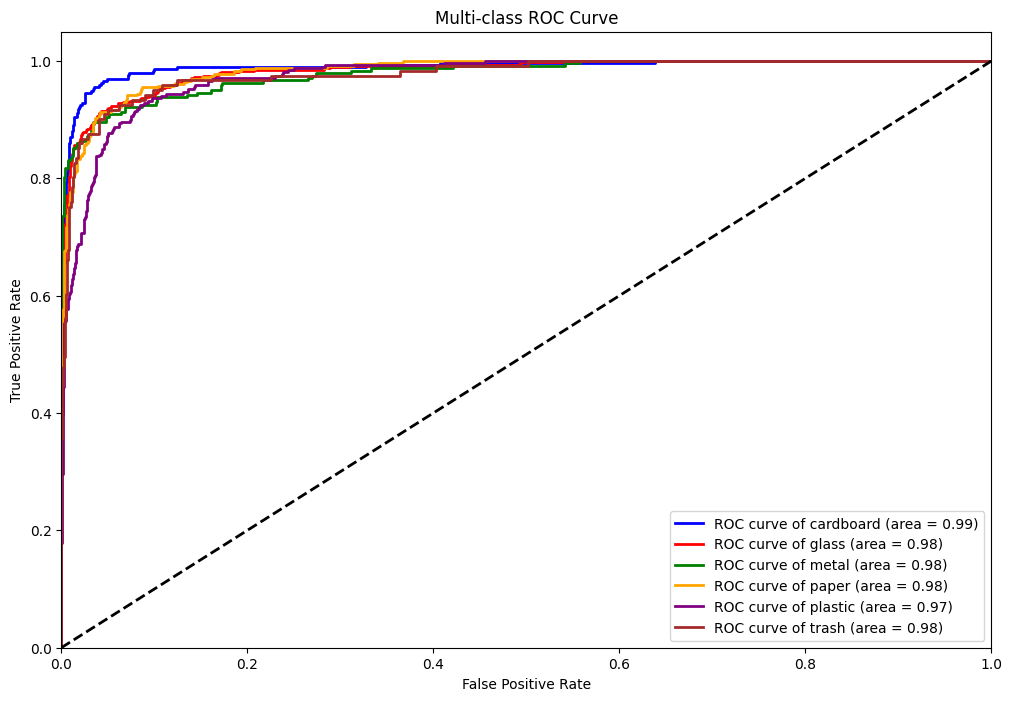

Created model performance dashboard at /content/model_performance_dashboard.png
All visualizations complete!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, roc_curve, auc
from itertools import cycle
from PIL import Image
import os

# 1. Training History Visualization
plt.figure(figsize=(15, 5))

# Plot training & validation accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training & validation loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('/content/training_history.png')
plt.show()

# 2. F1 Score Visualization
# Since we added a custom callback, F1 score won't be in history by default
if 'val_f1_score' in history.history:
    plt.figure(figsize=(8, 5))
    plt.plot(history.history['val_f1_score'], label='Validation F1 Score')
    plt.title('F1 Score')
    plt.xlabel('Epoch')
    plt.ylabel('F1 Score')
    plt.legend()
    plt.savefig('/content/f1_score_history.png')
    plt.show()

# 3. Confusion Matrix for Validation Set
plt.figure(figsize=(10, 8))
cm = confusion_matrix(true_classes, val_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Validation Confusion Matrix')
plt.savefig('/content/confusion_matrix.png')
plt.show()

# 4. Prediction Distribution
plt.figure(figsize=(10, 6))
plt.hist(val_pred_classes, bins=len(np.unique(val_pred_classes)), alpha=0.7)
plt.title('Distribution of Predictions')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks(np.unique(val_pred_classes))
plt.savefig('/content/prediction_distribution.png')
plt.show()

# 5. Class-wise Accuracy
# Use class indices from the dataset if available
try:
    class_names = list(val_dataset_tf.class_indices.keys())
except AttributeError:
    class_names = [f'Class {i}' for i in range(len(np.unique(true_classes)))]

class_accuracy = []

# Calculate accuracy per class
for i in range(len(class_names)):
    class_mask = (true_classes == i)
    if np.sum(class_mask) > 0:  # Avoid division by zero
        accuracy = np.sum(val_pred_classes[class_mask] == i) / np.sum(class_mask)
        class_accuracy.append(accuracy)
    else:
        class_accuracy.append(0)

# Plot class-wise accuracy
plt.figure(figsize=(12, 6))
plt.bar(range(len(class_names)), class_accuracy)
plt.title('Class-wise Accuracy')
plt.xlabel('Class')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(range(len(class_names)), class_names, rotation=45)
for i, v in enumerate(class_accuracy):
    plt.text(i, v + 0.02, f'{v:.2f}', ha='center')
plt.tight_layout()
plt.savefig('/content/class_accuracy.png')
plt.show()
# 6. ROC Curve for Multi-class (One-vs-Rest approach)
plt.figure(figsize=(12, 8))

# Get one-hot encoded true labels from the saved true_labels
y_test = true_labels[:len(val_pred_classes)]
y_score = val_preds  # Predicted probabilities

n_classes = y_test.shape[1]
fpr = dict()
tpr = dict()
roc_auc = dict()

# Compute ROC curve and ROC area for each class
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'brown'])
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve of {class_names[i]} (area = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve')
plt.legend(loc="lower right")
plt.savefig('/content/roc_curve.png')
plt.show()

# 7. Create a dashboard summary image
# Check if all the required images exist
image_paths = [
    '/content/training_history.png',
    '/content/confusion_matrix.png',
    '/content/class_accuracy.png',
    '/content/prediction_distribution.png'
]

existing_images = [path for path in image_paths if os.path.exists(path)]

if len(existing_images) >= 2:
    # Create a dashboard of existing images
    images = [Image.open(img_path) for img_path in existing_images]

    # Calculate the grid dimensions
    n_images = len(images)
    cols = min(2, n_images)
    rows = (n_images + cols - 1) // cols

    # Get max width and height for each column and row
    widths = [max(images[j].width for j in range(i, min(i+cols, n_images)))
              for i in range(0, n_images, cols)]
    heights = [max(images[i*cols + j].height for j in range(min(cols, n_images - i*cols)))
               for i in range(rows)]

    # Create the dashboard
    total_width = sum(widths)
    total_height = sum(heights)
    dashboard = Image.new('RGB', (total_width, total_height), (255, 255, 255))

    # Paste images
    y_offset = 0
    for i in range(rows):
        x_offset = 0
        for j in range(cols):
            idx = i * cols + j
            if idx < n_images:
                dashboard.paste(images[idx], (x_offset, y_offset))
                x_offset += images[idx].width
        y_offset += max(images[i*cols].height for i in range(min(cols, n_images - i*cols)))

    # Save the dashboard
    dashboard.save('/content/model_performance_dashboard.png')
    print("Created model performance dashboard at /content/model_performance_dashboard.png")

print("All visualizations complete!")

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from tensorflow_model_optimization.python.core.keras.compat import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
    roc_curve,
    auc
)
from itertools import cycle
from PIL import Image
import os

# Load the saved model
model_path = "/content/saved_model.h5"  # Update this path to where your model is saved
model = keras.models.load_model(model_path)

# Load test dataset
test_data_dir = "/content/Merged_Split/test"  # Update this path
batch_size = 32
img_size = (51, 51)  # Adjust based on your model's input size

test_datagen = ImageDataGenerator(
    rescale=1.0 / 255  # Only rescaling for test data
)

# Load the test dataset
test_dataset_tf = test_datagen.flow_from_directory(
    test_data_dir,  # Path to the test images
    target_size=(img_size[0], img_size[1]),
    batch_size=batch_size,
    class_mode='categorical',  # Adjust this to your specific task
    shuffle=False  # No shuffle for test data
)

# Calculate steps per epoch for test dataset
steps_per_epoch_test = np.ceil(test_dataset_tf.samples / batch_size).astype(int)

# Get true labels and class names
true_labels = test_dataset_tf.classes
class_names = list(test_dataset_tf.class_indices.keys())
num_classes = len(class_names)

# Predict using the model with specified steps
y_pred_probs = model.predict(test_dataset_tf, steps=steps_per_epoch_test)  # Predicted probabilities
y_pred_classes = np.argmax(y_pred_probs, axis=1)  # Convert to class labels

# 1. **Classification Report**
print("Classification Report:")
report = classification_report(true_labels, y_pred_classes, target_names=class_names)
print(report)

# Save the classification report
report_path = "/content/classification_report.txt"
with open(report_path, "w") as f:
    f.write(report)
print(f"Classification report saved at {report_path}")

# 2. **Confusion Matrix**
cm = confusion_matrix(true_labels, y_pred_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
confusion_matrix_path = "/content/confusion_matrix.png"
plt.savefig(confusion_matrix_path)
plt.show()  # Restored plt.show()
print(f"Confusion matrix saved at {confusion_matrix_path}")

# 3. **Accuracy, Precision, Recall, F1-score**
correct_predictions = np.sum(y_pred_classes == true_labels)
accuracy = correct_predictions / len(true_labels)

print(f"Test Accuracy: {accuracy:.4f}")

# 4. **Prediction Distribution**
plt.figure(figsize=(10, 6))
plt.hist(y_pred_classes, bins=num_classes, alpha=0.7)
plt.title("Distribution of Predictions")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(range(num_classes), class_names, rotation=45)
prediction_distribution_path = "/content/prediction_distribution.png"
plt.savefig(prediction_distribution_path)
plt.show()  # Restored plt.show()
print(f"Prediction distribution saved at {prediction_distribution_path}")

# 5. **ROC Curve for Multi-class Classification (One-vs-Rest)**
plt.figure(figsize=(12, 8))

# One-hot encode true labels
y_true_one_hot = tf.keras.utils.to_categorical(true_labels, num_classes)

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_one_hot[:, i], y_pred_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
colors = cycle(['blue', 'red', 'green', 'orange', 'purple', 'brown'])
for i, color in zip(range(num_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label=f'ROC curve of {class_names[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-class ROC Curve')
plt.legend(loc="lower right")
roc_curve_path = "/content/roc_curve.png"
plt.savefig(roc_curve_path)
plt.show()  # Restored plt.show()
print(f"ROC curve saved at {roc_curve_path}")

# 6. **Class-wise Accuracy**
class_accuracy = []
for i in range(num_classes):
    mask = (true_labels == i)
    if np.sum(mask) > 0:
        accuracy = np.sum(y_pred_classes[mask] == i) / np.sum(mask)
        class_accuracy.append(accuracy)
    else:
        class_accuracy.append(0)

plt.figure(figsize=(12, 6))
plt.bar(range(num_classes), class_accuracy)
plt.title("Class-wise Accuracy")
plt.xlabel("Class")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(range(num_classes), class_names, rotation=45)
for i, v in enumerate(class_accuracy):
    plt.text(i, v + 0.02, f'{v:.2f}', ha='center')
class_accuracy_path = "/content/class_accuracy.png"
plt.savefig(class_accuracy_path)
plt.show()  # Restored plt.show()
print(f"Class-wise accuracy plot saved at {class_accuracy_path}")

# 7. **Create a Performance Summary Dashboard**
image_paths = [
    confusion_matrix_path,
    prediction_distribution_path,
    roc_curve_path,
    class_accuracy_path
]

existing_images = [path for path in image_paths if os.path.exists(path)]

if len(existing_images) >= 2:
    images = [Image.open(img) for img in existing_images]

    cols = min(2, len(images))
    rows = (len(images) + cols - 1) // cols

    widths = [max(images[j].width for j in range(i, min(i+cols, len(images))))
              for i in range(0, len(images), cols)]
    heights = [max(images[i*cols + j].height for j in range(min(cols, len(images) - i*cols)))
               for i in range(rows)]

    total_width = sum(widths)
    total_height = sum(heights)
    dashboard = Image.new('RGB', (total_width, total_height), (255, 255, 255))

    y_offset = 0
    for i in range(rows):
        x_offset = 0
        for j in range(cols):
            idx = i * cols + j
            if idx < len(images):
                dashboard.paste(images[idx], (x_offset, y_offset))
                x_offset += images[idx].width
        y_offset += max(images[i*cols].height for i in range(min(cols, len(images) - i*cols)))

    dashboard_path = "/content/test_performance_dashboard.png"
    dashboard.save(dashboard_path)

    print(f"Test performance dashboard saved at {dashboard_path}")
    dashboard.show()

print("Testing complete!")

In [ ]:
import shutil
import os

# Define the target directories in your Google Drive
train_dir = "/content/drive/MyDrive/main model/Training"
test_dir = "/content/drive/MyDrive/main model/Testing"

# Create directories if they don't exist
os.makedirs(train_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

# Files to move
train_visuals = [
    "/content/training_history.png",
    "/content/f1_score_history.png",  # Only if exists
    "/content/confusion_matrix.png",  # Training confusion matrix
    "/content/class_accuracy.png",
    "/content/prediction_distribution.png",
    "/content/model_performance_dashboard.png"
    "/content/saved_model.h5"

]

test_visuals = [
    "/content/classification_report.txt",
    "/content/confusion_matrix.png",  # Testing confusion matrix
    "/content/class_accuracy.png",
    "/content/prediction_distribution.png",
    "/content/roc_curve.png",
    "/content/test_performance_dashboard.png"
]

# Move training visualizations
for file_path in train_visuals:
    if os.path.exists(file_path):
        shutil.copy(file_path, train_dir)

# Move testing visualizations
for file_path in test_visuals:
    if os.path.exists(file_path):
        shutil.copy(file_path, test_dir)

print(f"✅ All visualizations copied to Google Drive:\n- Training: {train_dir}\n- Testing: {test_dir}")


In [ ]:
pip install numpy==1.26.4 tensorflow==2.18.0 tensorflow-model-optimization==0.8.0 --force-reinstall

  Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached tensorflow_model_optimization-0.8.0-py2.py3-none-any.whl.metadata (904 bytes)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 kB 2.2 MB/s eta 0:00:00
Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.3 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 615.4/615.4 MB 2.9 MB/s eta 0:00:00
Using cached tensorflow_model_optimization-0.8.0-py2.py3-none-any.whl (242 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.5/126.5 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 152.9/152.9 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.9/5.9 MB 69.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 43.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 54.7 MB/s eta 0:00:00

# Test Model

In [ ]:
with quantize.quantize_scope():
  tF_model = keras.models.load_model(keras_file)

score = tf_model.evaluate(test_dataset_tf.take(1), verbose=1, steps=len(test_dataset))
print('Test Loss:', score[0])
print('Test Accuracy:', score[1])
print('Test F1Score:', score[2])

# Extended Testing (Do Before Writing Paper)

In [ ]:
# from sklearn.metrics import classification_report

# # Predict using the model
# y_true = []
# y_pred = []

# for x_batch, y_batch in test_dataset_tf:
#     # Convert true labels to class indices if they are one-hot encoded
#     y_true.extend(np.argmax(y_batch.numpy(), axis=1))  # Convert to class indices

#     # Predict and store predicted labels
#     y_pred_probs = tf_model.predict(x_batch)  # Get probabilities
#     y_pred.extend(np.argmax(y_pred_probs, axis=1))  # Convert to class indices

# # Generate the classification report
# report = classification_report(y_true, y_pred, digits=4)
# print("Classification Report:")
# print(report)


# Convert to TFLite

In [ ]:
quantization = "float"
assert quantization == "integer" or quantization == "float", f"Invalid {quantization} option"

subset = 1

# Use the first 300 images in the post-training quantization.
def representative_dataset():
  for i in range(subset):
    image, _ = next(iter(train_dataset_tf))
    yield [image]

with quantize.quantize_scope():
  tF_model = keras.models.load_model(keras_file)
converter = tf.lite.TFLiteConverter.from_keras_model(tf_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter._experimental_disable_per_channel_quantization_for_dense_layers = True
converter.representative_dataset = representative_dataset

if quantization == "integer":
  converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
  converter.inference_input_type = tf.int8
  converter.inference_output_type = tf.int8

tflite_model = converter.convert()
quant_file = 'model.tflite'
open(quant_file, 'wb').write(tflite_model)

# Compare File Sizes Between Base and Tflite Model

In [ ]:
import os


float_converter = tf.lite.TFLiteConverter.from_keras_model(tf_model)
float_tflite_model = float_converter.convert()


float_file = "float_model.tflite"

with open(float_file, 'wb') as f:
  f.write(float_tflite_model)

print("Float model in Mb:", os.path.getsize(float_file) / float(2**20))
print("Quantized model in Mb:", os.path.getsize(quant_file) / float(2**20))

# Evalute TFLite Model

In [ ]:
from sklearn.metrics import classification_report

# Evaluate the fully quantized model.
interpreter = tf.lite.Interpreter(model_path=quant_file)
interpreter.resize_tensor_input(0, [1, IMG_DIM, IMG_DIM, 3])
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()
input_index = input_details[0]['index']
output_index = output_details[0]['index']

print(f"Input shape: {input_details[0]['shape_signature']}, Output shape: {output_details[0]['shape_signature']}")

total_seen = 0
y_true = []
y_pred = []

# Testing the entire dataset is too slow. Verifying only 300 of 10k samples.
print('Evaluate TFLite model.')

for imgs, labels in test_dataset_tf.take(subset):
    for img, label in zip(imgs, labels):
        img = np.expand_dims(np.array(img, dtype=np.float32), axis=0)
        if quantization == "integer":
          img = img  * 255.0
          img = img.astype(np.int8)
        interpreter.set_tensor(input_index, img)
        interpreter.invoke()
        predictions = interpreter.get_tensor(output_index)

        # Store true and predicted labels
        y_true.append(np.argmax(label))  # Ground truth
        y_pred.append(np.argmax(predictions))  # Predicted class

# Calculate metrics
print('Classification Report:')
report = classification_report(y_true, y_pred, digits=4)
print(report)

# If needed, you can parse specific metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')


print(f"Base Accuracy: {score[1]:.4f}")
print(f"Tflite Accuracy: {accuracy:.4f}")
print(f"Base F1Score: {score[2]:.4f}")
print(f"Tflite F1 Score: {f1:.4f}")

print(f"Tflite Precision: {precision:.4f}")
print(f"Tflite Recall: {recall:.4f}")

np.testing.assert_allclose(score[1], accuracy, rtol=0.2, atol=0.2)

# Visualize Model Ops

In [ ]:
import model_explorer

model_explorer.visualize(quant_file)

# Export Model as Header File for Tflite-Micro

In [ ]:
!xxd -i {quant_file} > model.h
!cat model.h | sed 's/unsigned char [a-zA-Z_]\+/#define IMG_DIM {IMG_DIM}\nalignas(16) const unsigned char model/g'| sed 's/unsigned int [a-zA-Z_]\+/const unsigned int model_len/g'> temp.h
!mv temp.h model.h
!cat model.h | head -n 2
!cat model.h | tail -n 1

# Export `image_data.h` for testing inference on MCU

In [ ]:
# Number of classes in the dataset
NUM_CLASSES = len(class_indices)

# Initialize a dictionary to store one sample per class
sample_per_class = {i: None for i in range(NUM_CLASSES)}
found_classes = set()

# Loop through the validation dataset batches until we collect one sample per class
for x_batch, y_batch in val_dataset_tf:
    # Convert the batch to numpy arrays
    images = x_batch.numpy()
    labels = y_batch.numpy()

    # Loop through each sample in the batch
    for i, label in enumerate(labels):
        class_idx = np.argmax(label)  # Find the class index of the one-hot label

        # If we haven't collected a sample for this class, add it
        if class_idx not in found_classes:
            sample_per_class[class_idx] = images[i]
            found_classes.add(class_idx)

        # Stop if we've found a sample for each class
        if len(found_classes) == NUM_CLASSES:
            break

    if len(found_classes) == NUM_CLASSES:
        break

id_to_class_name = {v: k for k, v in class_indices.items()}

# Define the path for the header file
header_file_path = 'image_data.h'

# Open the file in write mode
with open(header_file_path, 'w') as f:
    # Write a comment at the top of the header file
    f.write("// This header file contains int8 image data arrays for each class\n\n")

    # Loop through each sample in the sample_per_class dictionary
    for class_id, image in sample_per_class.items():
        # Get the class name from the class ID
        class_name = id_to_class_name[class_id]
        image_array = np.array(image, dtype=np.float32).flatten()

        if quantization == "integer":
          image_array = image_array  * 255.0
          image_array = image_array.astype(np.int8)

        # Write the array definition to the header file
        f.write(f"// Class {class_id}: {class_name}\n")
        f.write(f"{'int8_t' if image_array.dtype==np.int8 else 'float'} {class_name}[] = {{\n")

        # Write the pixel values to the file
        pixel_values = ", ".join(map(str, image_array))
        f.write(f"    {pixel_values}\n")
        f.write("};\n\n")
        break


print(f"Header file '{header_file_path}' has been created successfully.")

# Full Quantization [Deprecated, Don't Run This]

---



In [ ]:
# import numpy as np
# def representative_dataset():
#   for data in val_dataset_tf.take(1).take(1):
#     yield [data[0].numpy()]

# converter = tf.lite.TFLiteConverter.from_keras_model(tf_model)
# converter.optimizations = [tf.lite.Optimize.DEFAULT]
# converter.representative_dataset = representative_dataset
# converter._experimental_disable_per_channel_quantization_for_dense_layers = True
# converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
# converter.inference_input_type = tf.uint8  # or tf.uint8
# converter.inference_output_type = tf.uint8  # or tf.uint8
# tflite_noquant_model = converter.convert()



# interpreter = tf.lite.Interpreter(model_content=tflite_noquant_model)
# interpreter.allocate_tensors()
# input_details = interpreter.get_input_details()
# output_details = interpreter.get_output_details()
# input_type = input_details[0]['dtype']
# output_type = output_details[0]['dtype']

# print("Input type:", input_type)
# print("Output type:", output_type)

# !rm model.tflite
# !rm model.h
# with open("model.tflite", 'wb') as f:
#   f.write(tflite_noquant_model)

# !xxd -i model.tflite > model.h
# !cat model.h | sed 's/unsigned char [a-zA-Z_]\+/#define IMG_DIM {IMG_DIM}\nalignas(16) const unsigned char model/g'| sed 's/unsigned int [a-zA-Z_]\+/const unsigned int model_len/g'> temp.h
# !mv temp.h model.h
# !cat model.h | head -n 1
# !cat model.h | tail -n 1


# Transferring Weights [Deprecated, Don't Run This]


In [ ]:
# import torch
# import numpy as np
# import tensorflow as tf

# # 1. Collect weights from the PyTorch model
# torch_weights = []

# print("\nTorch Model Parameter Shapes (Sequential):")
# for idx, (name, module) in enumerate(torch_model.named_modules()):
#   # For BatchNorm2d, also collect running mean and variance
#   if isinstance(module, torch.nn.BatchNorm2d):
#       running_mean = module.running_mean.detach().cpu().numpy()
#       running_var = module.running_var.detach().cpu().numpy()
#       gamma = module.weight.detach().cpu().numpy()  # scale
#       beta = module.bias.detach().cpu().numpy()     # shift
#       torch_weights.append(gamma)
#       torch_weights.append(beta)
#       torch_weights.append(running_mean)
#       torch_weights.append(running_var)
#       print(f"Layer {idx}: {name}, Running Mean Shape: {running_mean.shape}, Running Var Shape: {running_var.shape}")
#       continue

#   # Check if the module has `weight` and `bias` attributes
#   if hasattr(module, 'weight') and module.weight is not None:
#       weight = module.weight.detach().cpu().numpy()
#       torch_weights.append(weight)
#       print(f"Layer {idx}: {name}, Weight Shape: {weight.shape}")

#   if hasattr(module, 'bias') and module.bias is not None:
#       bias = module.bias.detach().cpu().numpy()
#       torch_weights.append(bias)
#       print(f"Layer {idx}: {name}, Bias Shape: {bias.shape}")



# # 2. Map PyTorch weights to TensorFlow layers by sequence
# print("\nTensorFlow Model Parameter Shapes (Sequential):")
# torch_weight_idx = 0


# for idx, layer in enumerate(tf_model.layers):
#   # Handle regular layers with weight and bias (e.g., Conv2D, Dense)
#   if layer.weights:  # if the layer has weights
#     temp = torch_weights[0 : len(layer.weights)]
#     torch_weights = torch_weights[len(layer.weights):]
#     print(f"Layer {idx}: {layer.name}")
#     for j in range(len(layer.weights)):
#       print(f"\tWeight: {layer.weights[j].name} \n\t Shape conversion: PyTorch {temp[j].shape} -> Tensorflow {layer.weights[j].shape} ")
#       layer.weights[j].assign(tf.reshape(temp[j], shape=layer.weights[j].shape))



# print("\nWeights transferred successfully from PyTorch to TensorFlow!")


# Splitting Dataset Into Train, Test, and, Split Subdirectories [Deprecated, Don't Run This]


In [ ]:
# import logging
# logging.getLogger("tensorflow").setLevel(logging.DEBUG)

# import tensorflow as tf
# from tensorflow import keras
# import numpy as np
# import pathlib
# import os
# import shutil
# import numpy as np
# from sklearn.model_selection import train_test_split

# # Path to the dataset
# dataset_dir = '/content/Merged'
# output_dir = '/content/Merged_Split'  # Where to save the split dataset

# # List of all class labels (subfolder names)
# class_labels = os.listdir(dataset_dir)
# class_labels = [label for label in class_labels if os.path.isdir(os.path.join(dataset_dir, label))]  # Filter out any non-directories

# # Create directories for train, val, and test splits
# split_dirs = ['train', 'val', 'test']
# for split in split_dirs:
#     split_path = os.path.join(output_dir, split)
#     if not os.path.exists(split_path):
#         os.makedirs(split_path)
#     for label in class_labels:
#         os.makedirs(os.path.join(split_path, label))

# # Iterate over each class and split the dataset
# for label in class_labels:
#     label_dir = os.path.join(dataset_dir, label)
#     images = os.listdir(label_dir)
#     images = [os.path.join(label_dir, img) for img in images if os.path.isfile(os.path.join(label_dir, img))]

#     # Split the images into train, val, and test sets
#     train_images, test_images = train_test_split(images, test_size=0.2, random_state=42)
#     val_images, test_images = train_test_split(test_images, test_size=0.5, random_state=42)

#     # Move the images to their respective folders
#     for split, image_list in zip(['train', 'val', 'test'], [train_images, val_images, test_images]):
#         for image in image_list:
#             shutil.copy(image, os.path.join(output_dir, split, label, os.path.basename(image)))

# # Check the directory structure
# print("Dataset split completed!")
# !zip -r Merged_Split.zip Merged_Split
# from google.colab import drive
# drive.mount('/content/drive')
# !cp -rf Merged_Split.zip /content/drive/MyDrive/TrashDatasetMerged/
